# Email Classification Using Machine Learning

### 1. Import Libraries

In [95]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import kagglehub
import warnings
warnings.filterwarnings("ignore")
sns.set_style("ticks")

### 2. Load Dataset

In [8]:
# import raw data
raw_data_df = pd.read_csv("dataset\emails.csv", encoding='latin-1')

### 3. Data Pre-Processing

In [10]:
raw_data_df.head(5)

,text,spam
0,Subject: naturally irresistible your corporate...,1
1,Subject: the stock trading gunslinger fanny i...,1
2,Subject: unbelievable new homes made easy im ...,1
3,Subject: 4 color printing special request add...,1
4,"Subject: do not have money , get software cds ...",1


In [12]:
raw_data_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5728 entries, 0 to 5727
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   text    5728 non-null   str  
 1   spam    5728 non-null   int64
dtypes: int64(1), str(1)
memory usage: 89.6 KB


In [22]:
raw_data_df.shape

(5728, 2)

In [23]:
raw_data_df.isnull().sum()

text    0
spam    0
dtype: int64

In [31]:
raw_data_df.duplicated().sum()

np.int64(33)

In [30]:
raw_data_df["text"][raw_data_df["text"].duplicated()]

2155    Subject: research allocations to egm  hi becky...
2260    Subject: departure of grant masson  the resear...
2412    Subject: re : schedule and more . .  jinbaek ,...
2473    Subject: day off tuesday  stinson ,  i would l...
2763    Subject: re : your mail  zhendong ,  dr . kami...
3123    Subject: re : grades  pam ,  the students rese...
3152    Subject: tiger evals - attachment  tiger hosts...
3248    Subject: re : i am zhendong  zhendong ,  thank...
3249    Subject: hello from enron  dear dr . mcmullen ...
3387    Subject: term paper  dr . kaminski ,  attached...
3573    Subject: telephone interview with the enron re...
3660    Subject: re : summer work . .  jinbaek ,  this...
3690    Subject: re : weather and energy price data  m...
3823    Subject: research get - together at sandeep ko...
4203    Subject: re : willow and pathstar evaluations ...
4390    Subject: re : eprm 2001 houston  layla ,  my a...
4394    Subject: vp & director count for the research ...
4771    Subjec

In [33]:
df_cleaned = raw_data_df.drop_duplicates(subset=["text"], keep="first")

In [34]:
df_cleaned.shape

(5695, 2)

In [37]:
df_cleaned

,text,spam
0,Subject: naturally irresistible your corporate...,1
1,Subject: the stock trading gunslinger fanny i...,1
2,Subject: unbelievable new homes made easy im ...,1
3,Subject: 4 color printing special request add...,1
4,"Subject: do not have money , get software cds ...",1
...,...,...
5723,Subject: re : research and development charges...,0
5724,"Subject: re : receipts from visit jim , than...",0
5725,Subject: re : enron case study update wow ! a...,0
5726,"Subject: re : interest david , please , call...",0


We would encode the target variable (label) to numeric values using the sklearn Label Encoder. In this case, the data is already encoded as 1 for 'not spam' and 0 for 'spam', so we can skip this step.

# 4. Exploratory Data Analysis

#### 4.1 Distribution of Spam and Not Spam

In [54]:
df_cleaned["spam"].value_counts()

spam
0    4327
1    1368
Name: count, dtype: int64

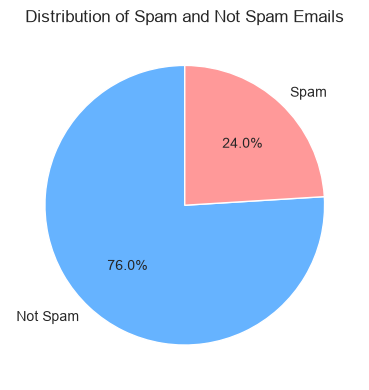

In [77]:
plt.figure(figsize=(8,4))
plt.pie(df_cleaned["spam"].value_counts(), labels=["Not Spam", "Spam"], autopct="%1.1f%%", startangle=90, colors=["#66b3ff", "#ff9999"])
plt.title("Distribution of Spam and Not Spam Emails")
plt.tight_layout()
plt.show()

The spam and not spam classes are imbalanced. So we need to observe how this could impact the model. We could use SMOTE or ADASYN to boost the minority class. Or even implement an advanced hybrid methods like SMOTE-Tomek or SMOTE-ENN.

In [52]:
# Import the NLTK library for natural language processing tasks
import nltk

In [118]:
# Download the 'punkt' tokenizer models from NLTK, which are used for tokenizing text into sentences and words
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('punkt_tab')


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\maisha.bopape\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\maisha.bopape\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\maisha.bopape\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

#### 4.2 Number of characters, words and sentences in each mail

In [63]:
df_cleaned["num_chars"] = df_cleaned["text"].apply(len)
df_cleaned["num_words"] = df_cleaned["text"].apply(lambda x: len(nltk.word_tokenize(x)))
df_cleaned["num_sentences"] = df_cleaned["text"].apply(lambda x: len(nltk.sent_tokenize(x)))
df_cleaned.head(15)

,text,spam,num_chars,num_words,num_sentences
0,Subject: naturally irresistible your corporate...,1,1484,325,11
1,Subject: the stock trading gunslinger fanny i...,1,598,90,1
2,Subject: unbelievable new homes made easy im ...,1,448,88,4
3,Subject: 4 color printing special request add...,1,500,99,5
4,"Subject: do not have money , get software cds ...",1,235,53,9
5,"Subject: great nnews hello , welcome to medzo...",1,478,85,3
6,Subject: here ' s a hot play in motion homela...,1,9340,1704,72
7,Subject: save your money buy getting this thin...,1,446,97,9
8,Subject: undeliverable : home based business f...,1,507,122,3
9,Subject: save your money buy getting this thin...,1,446,97,9


#### 4.1.1 Percentile Analysis for Spam Emails

In [65]:
df_cleaned[df_cleaned["spam"]==1].describe()

,spam,num_chars,num_words,num_sentences
count,1368.0,1368.000000,1368.000000,1368.000000
mean,1.0,1317.257310,267.896199,18.274123
std,0.0,2271.372893,451.623124,28.130434
min,1.0,18.000000,5.000000,1.000000
25%,1.0,401.500000,80.000000,6.000000
50%,1.0,693.500000,141.000000,11.000000
75%,1.0,1250.250000,252.000000,18.000000
max,1.0,28432.000000,6131.000000,438.000000


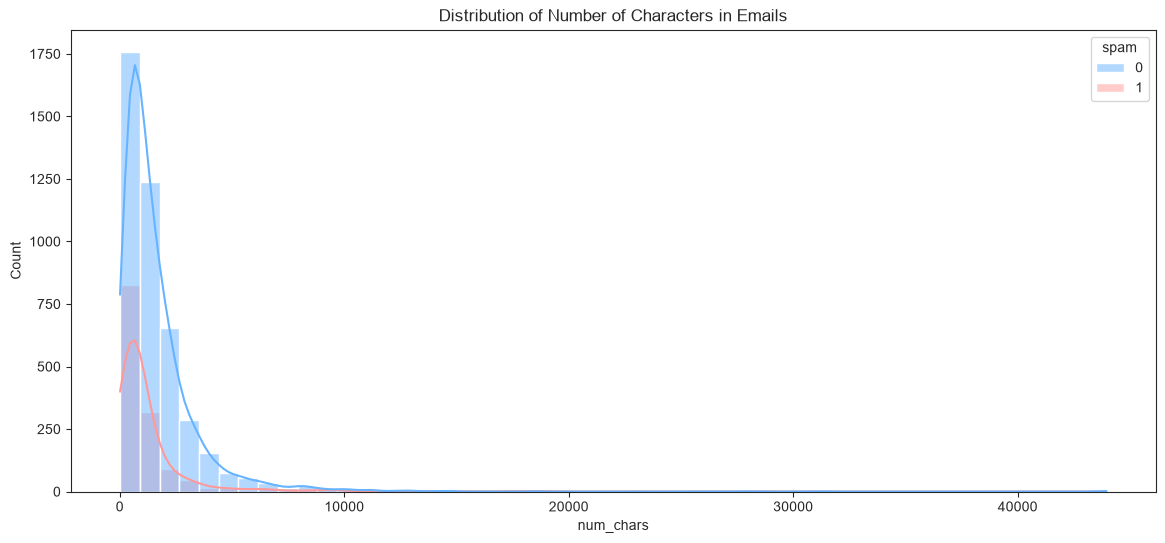

In [96]:
plt.figure(figsize=(14, 6))
sns.histplot(data=df_cleaned, x="num_chars", hue="spam", palette=["#66b3ff", "#ff9999"], kde=True, bins=50)
plt.title("Distribution of Number of Characters in Emails")
plt.show()

#### 4.1.2 Percentile Analysis for Non-Spam Emails

In [97]:
df_cleaned[df_cleaned["spam"]==0].describe()

,spam,num_chars,num_words,num_sentences
count,4327.0,4327.000000,4327.000000,4327.000000
mean,0.0,1634.200139,347.283799,19.838225
std,0.0,1965.016383,407.227757,38.124564
min,0.0,13.000000,3.000000,1.000000
25%,0.0,577.500000,120.000000,7.000000
50%,0.0,1122.000000,240.000000,13.000000
75%,0.0,2037.500000,440.500000,22.000000
max,0.0,43952.000000,8479.000000,1565.000000


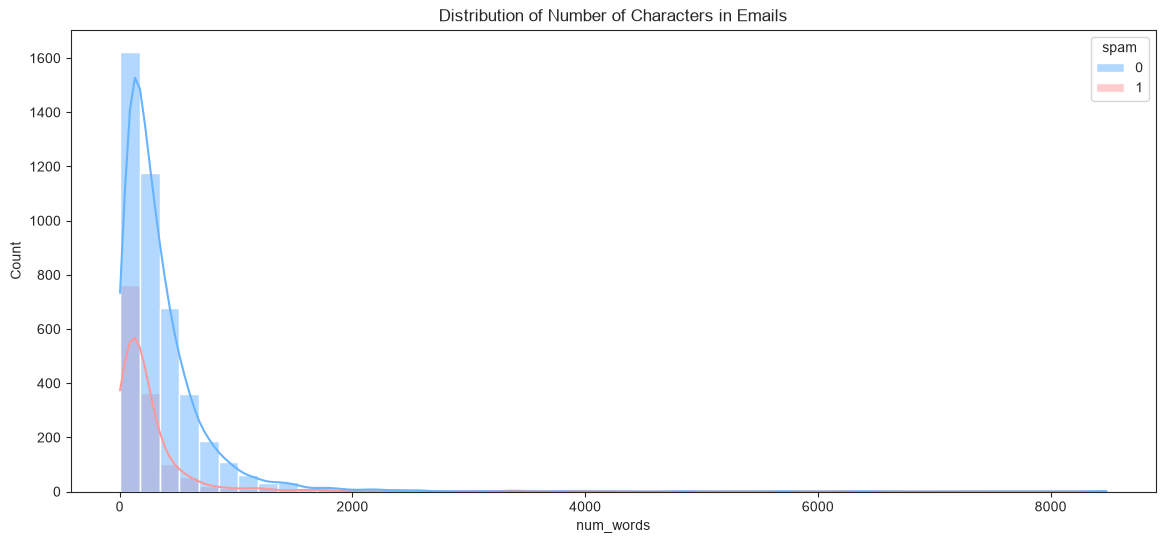

In [98]:
plt.figure(figsize=(14, 6))
sns.histplot(data=df_cleaned, x="num_words", hue="spam", palette=["#66b3ff", "#ff9999"], kde=True, bins=50)
plt.title("Distribution of Number of Characters in Emails")
plt.show()

#### 4.3 Relationship analysis

##### 4.3.1 Pairplots

<Figure size 1500x800 with 0 Axes>

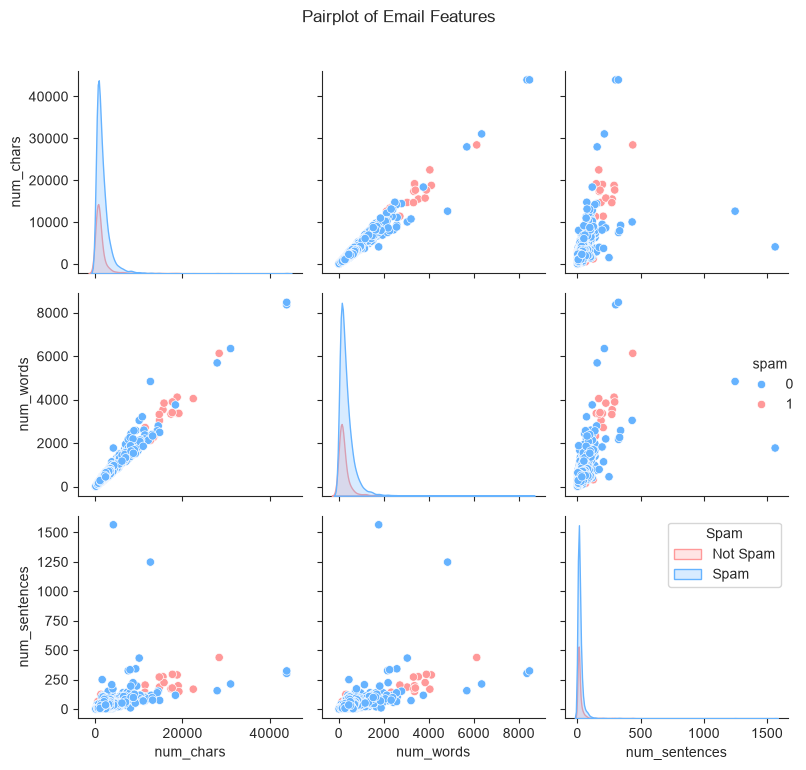

In [101]:
plt.figure(figsize=(15, 8))
sns.pairplot(df_cleaned, hue="spam", palette=["#66b3ff", "#ff9999"])
plt.suptitle("Pairplot of Email Features", y=1.02)
plt.legend(title="Spam", loc="upper right", labels=["Not Spam", "Spam"])
plt.tight_layout()
plt.show()

##### 4.3.2 Heatmap Analysis

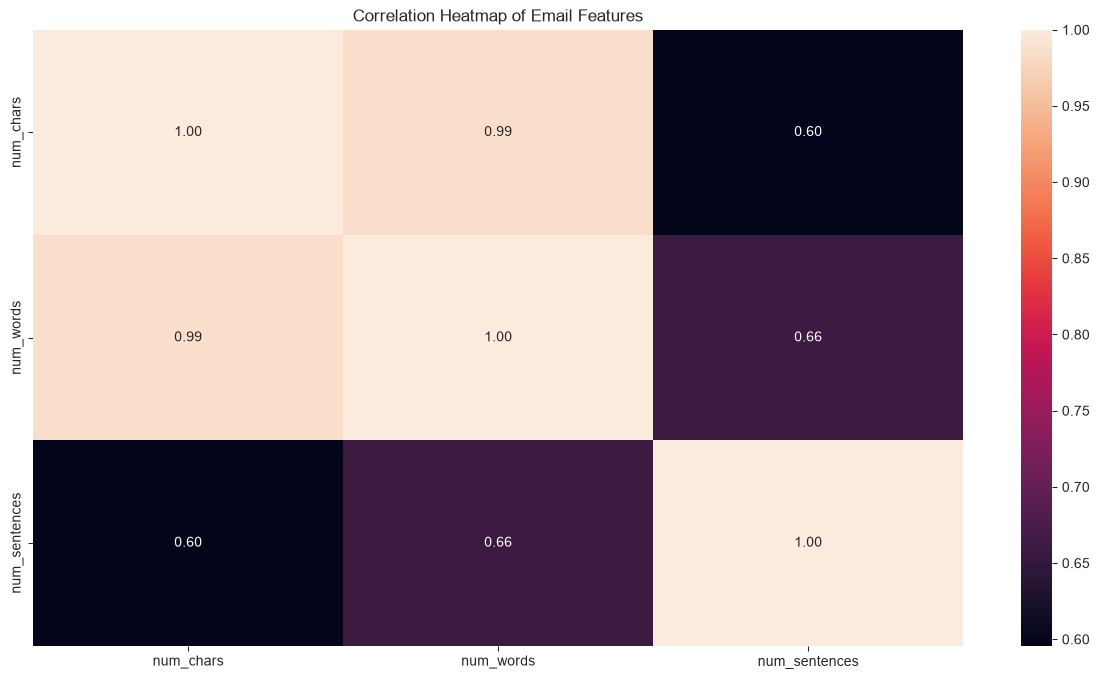

<Figure size 640x480 with 0 Axes>

In [116]:
plt.figure(figsize=(15,8))
sns.heatmap(df_cleaned.iloc[:,[2,3,4]].corr(), annot=True, fmt=".2f")
plt.title("Correlation Heatmap of Email Features")
plt.show()
plt.tight_layout()

## 5. Natural Language Processing
>- Convert text to lower case
>- Tokenization
>- Remove special characters
>- Remove panctuation and stop words
>- Stemming

In [119]:
from nltk.stem import PorterStemmer
from nltk.corpus import stopwords
import string

# Initialize the PorterStemmer for stemming words
ps = PorterStemmer()

# Initialize the set of English stopwords
stop_words = set(stopwords.words("english"))

# Initialize the set of punctuation marks
punctuation = set(string.punctuation)

In [125]:
# Define a helper functions to preprocess the text data
def TextTransform(text):
    text = text.lower()  # Convert text to lowercase
    text = nltk.word_tokenize(text)  # Tokenize the text into words
    y = []
    for i in text:
        if i.isalnum():  # Keep only alphanumeric tokens
            y.append(i)
    text = y[:]
    y.clear()

    for i in text:
        if i not in stop_words and i not in punctuation:  # Remove stopwords and punctuation
            y.append(i)
    text = y[:]      
    y.clear()

    for i in text:
        y.append(ps.stem(i))  # Apply stemming to each word
    return " ".join(y)  # Join the processed words back into a single string

Apply the TextTransform helper to the dataset.

In [127]:
df_cleaned["text_transformed"] = df_cleaned["text"].apply(TextTransform)

In [130]:
df_cleaned.head(5)

,text,spam,num_chars,num_words,num_sentences,text_transformed
0,Subject: naturally irresistible your corporate...,1,1484,325,11,subject natur irresist corpor ident lt realli ...
1,Subject: the stock trading gunslinger fanny i...,1,598,90,1,subject stock trade gunsling fanni merril muzo...
2,Subject: unbelievable new homes made easy im ...,1,448,88,4,subject unbeliev new home made easi im want sh...
3,Subject: 4 color printing special request add...,1,500,99,5,subject 4 color print special request addit in...
4,"Subject: do not have money , get software cds ...",1,235,53,9,subject money get softwar cd softwar compat gr...


#### 5.2 Word Frequency or Importance

In [ ]:
from wordcloud import WordCloud

##### 5.2.1 Word Cloud for Spam Emails

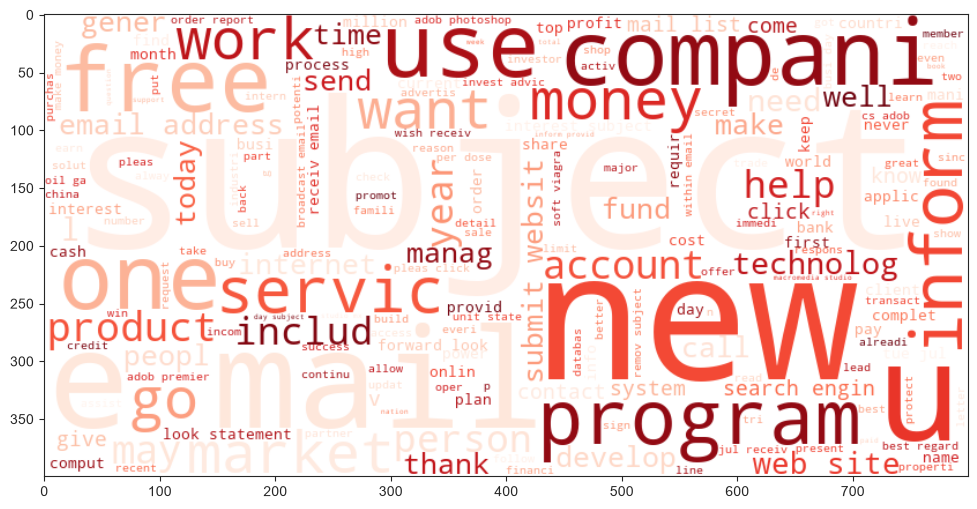

In [137]:
# Initialize the WordCloud object with desired parameters
wc = WordCloud(width=800, height=400, background_color='white', colormap='Reds', max_words=200)

spam_wordcloud = wc.generate(df_cleaned[df_cleaned["spam"]==1]["text_transformed"].str.cat(sep=" "))

plt.figure(figsize=(12, 6))
plt.imshow(spam_wordcloud, interpolation='bilinear')

##### 5.2.2 Word Frequency for Spam Emails

In [139]:
spam_corpus = []
for msg in df_cleaned[df_cleaned["spam"]==1]["text_transformed"].tolist():
    for word in msg.split():
        spam_corpus.append(word)

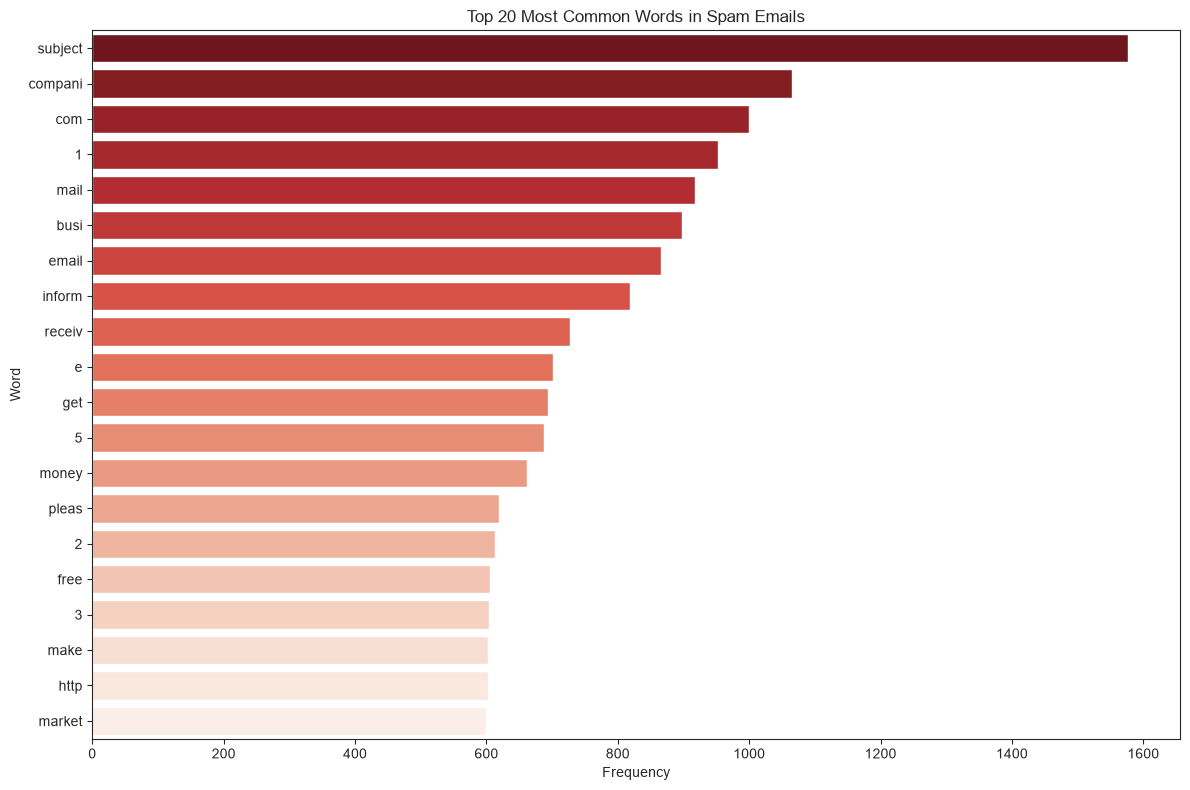

In [ ]:
from collections import Counter

most_common_spam = pd.DataFrame(
    Counter(spam_corpus).most_common(20),
    columns=["Word", "Frequency"]
)

plt.figure(figsize=(12, 8))

ax = sns.barplot(
    data=most_common_spam,
    x="Frequency",
    y="Word",
    hue="Word",
    palette="Reds_r",
    legend=False
)

ax.set_title("Top 20 Most Common Words in Spam Emails")
ax.set_xlabel("Frequency")
ax.set_ylabel("Word")

plt.tight_layout()
plt.show()

##### 5.2.3 Word Cloud for Spam Emails

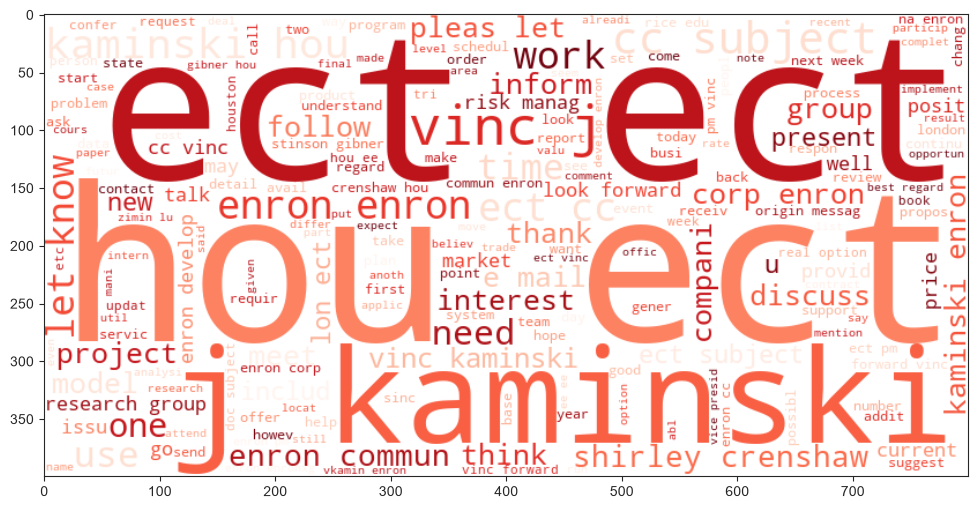

In [163]:
# Initialize the WordCloud object with desired parameters
wc = WordCloud(width=800, height=400, background_color='white', colormap='Reds', max_words=200)

spam_wordcloud = wc.generate(df_cleaned[df_cleaned["spam"]==0]["text_transformed"].str.cat(sep=" "))

plt.figure(figsize=(12, 6))
plt.imshow(spam_wordcloud, interpolation='bilinear')

##### 5.2.4 Word Frequency for Spam Emails

In [164]:
non_spam_corpus = []
for msg in df_cleaned[df_cleaned["spam"]==0]["text_transformed"].tolist():
    for word in msg.split():
        non_spam_corpus.append(word)

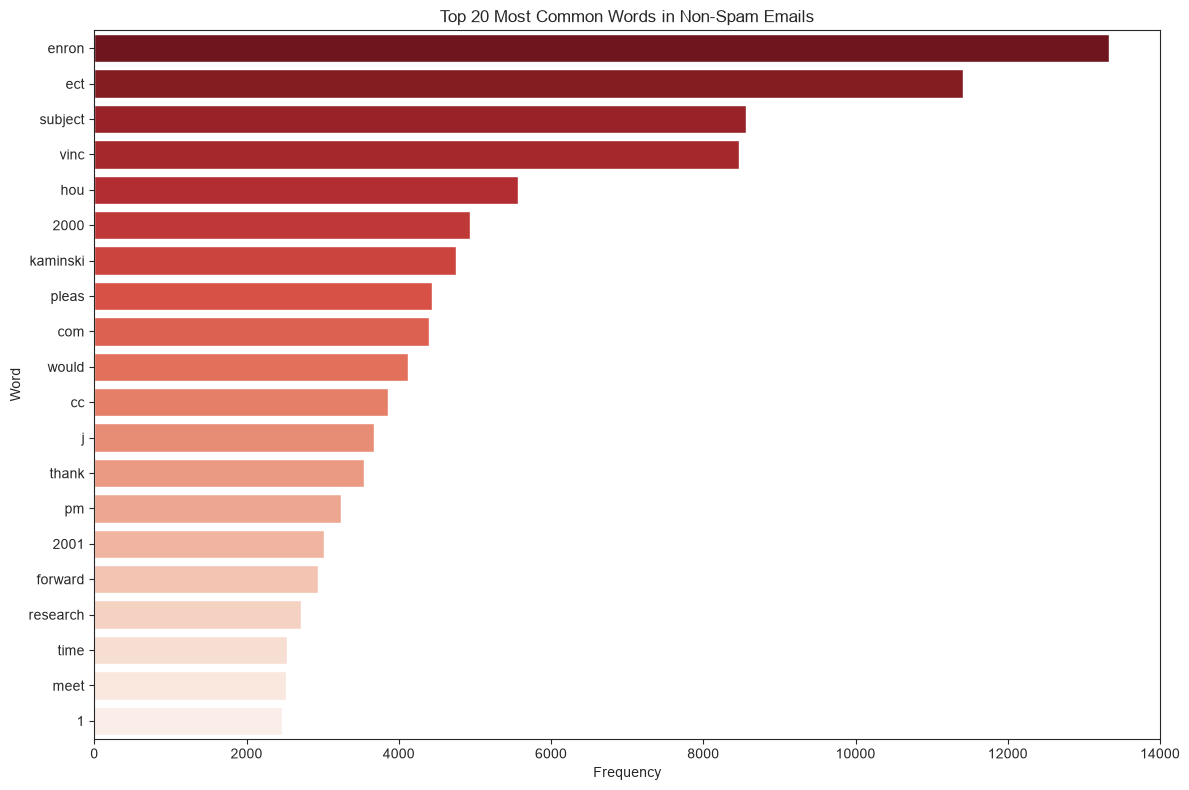

In [165]:
most_common_non_spam = pd.DataFrame(
    Counter(non_spam_corpus).most_common(20),
    columns=["Word", "Frequency"]
)

plt.figure(figsize=(12, 8))

ax = sns.barplot(
    data=most_common_non_spam,
    x="Frequency",
    y="Word",
    hue="Word",
    palette="Reds_r",
    legend=False
)

ax.set_title("Top 20 Most Common Words in Non-Spam Emails")
ax.set_xlabel("Frequency")
ax.set_ylabel("Word")

plt.tight_layout()
plt.show()

## 6. Machine Learning Model

In [189]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, precision_score, recall_score, f1_score
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier, BaggingClassifier, ExtraTreesClassifier
from xgboost import XGBClassifier

#### 6.1 Fearture Extraction

In [179]:
cv = CountVectorizer()
tfidf = TfidfVectorizer(max_features=3000)

# Fit and transform the text data using CountVectorizer
X = tfidf.fit_transform(df_cleaned["text_transformed"]).toarray()
print(f"Shape of the feature matrix: {X.shape}")

y = df_cleaned["spam"].values
print(f"Shape of the target vector: {y.shape}")

Shape of the feature matrix: (5695, 3000)
Shape of the target vector: (5695,)


#### 6.2 Train-Test Split

In [180]:
Xtrain, Xtest, ytrain, ytest = train_test_split(X, y, test_size=0.2, random_state=42)

#### 6.3 Model Training

##### 6.3.1 Gaussian Naive Bayes

In [182]:
gnb_model = GaussianNB()
gnb_model.fit(Xtrain, ytrain)
y_pred = gnb_model.predict(Xtest)
print("="*100)
print(f"Accuracy of GaussianNB model: {accuracy_score(ytest, y_pred):.4f}")
print(f"Classification Report:\n{classification_report(ytest, y_pred)}")
print(f"Confusion Matrix:\n{confusion_matrix(ytest, y_pred)}")


Accuracy of GaussianNB model: 0.9596
Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.99      0.97       843
           1       0.97      0.87      0.92       296

    accuracy                           0.96      1139
   macro avg       0.96      0.93      0.95      1139
weighted avg       0.96      0.96      0.96      1139

Confusion Matrix:
[[836   7]
 [ 39 257]]


##### 6.1.2  Multinomial Naives Bayes

In [183]:
mnb_model = MultinomialNB()
mnb_model.fit(Xtrain, ytrain)
y_pred = mnb_model.predict(Xtest)
print("="*100)
print(f"Accuracy of MultinomialNB model: {accuracy_score(ytest, y_pred):.4f}")
print(f"Classification Report:\n{classification_report(ytest, y_pred)}")
print(f"Confusion Matrix:\n{confusion_matrix(ytest, y_pred)}")


Accuracy of MultinomialNB model: 0.9807
Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       843
           1       0.99      0.94      0.96       296

    accuracy                           0.98      1139
   macro avg       0.98      0.97      0.97      1139
weighted avg       0.98      0.98      0.98      1139

Confusion Matrix:
[[839   4]
 [ 18 278]]


##### 6.1.3 Bernoulli Naive Bayes

In [186]:
bnb_model = BernoulliNB()
bnb_model.fit(Xtrain, ytrain)
y_pred = bnb_model.predict(Xtest)
print("="*100)
print(f"Accuracy of BernoulliNB model: {accuracy_score(ytest, y_pred):.4f}")
print(f"Classification Report:\n{classification_report(ytest, y_pred)}")
print(f"Confusion Matrix:\n{confusion_matrix(ytest, y_pred)}")


Accuracy of BernoulliNB model: 0.9421
Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.92      0.96       843
           1       0.82      1.00      0.90       296

    accuracy                           0.94      1139
   macro avg       0.91      0.96      0.93      1139
weighted avg       0.95      0.94      0.94      1139

Confusion Matrix:
[[777  66]
 [  0 296]]


##### 6.1.4 Various Model Training

In [ ]:
# Initialize other machine learning models for comparison
gnb_model = GaussianNB()
mnb_model = MultinomialNB()
bnb_model = BernoulliNB()
knc_model = KNeighborsClassifier()
svc_model = SVC(kernel='sigmoid', gamma='auto')
lrc_model = LogisticRegression(solver='liblinear', random_state=42, penalty='l1')
dtc_model = DecisionTreeClassifier(max_depth=5, random_state=42)
rfc_model = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)
gbc_model = GradientBoostingClassifier(n_estimators=50, learning_rate=0.1, max_depth=5, random_state=42)
abc_model = AdaBoostClassifier(n_estimators=50, learning_rate=0.1, random_state=42)
bgc_model = BaggingClassifier(n_estimators=50, random_state=42)
etc_model = ExtraTreesClassifier(n_estimators=50, random_state=42)
xgb_model = XGBClassifier(n_estimators=50, learning_rate=0.1, random_state=42)

classifiers = {
    "GaussianNB": gnb_model,
    "MultinomialNB": mnb_model,
    "BernoulliNB": bnb_model,
    "SVC": svc_model,
    "LogisticRegression": lrc_model,
    "KNeighborsClassifier": knc_model,
    "DecisionTreeClassifier": dtc_model,
    "RandomForestClassifier": rfc_model,
    "GradientBoostingClassifier": gbc_model,
    "AdaBoostClassifier": abc_model,
    "BaggingClassifier": bgc_model,
    "ExtraTreesClassifier": etc_model,
    "XGBClassifier": xgb_model
}

In [ ]:
def train_and_evaluate_model(model, Xtrain, ytrain, Xtest, ytest):
    model.fit(Xtrain, ytrain)
    y_pred = model.predict(Xtest)
    accuracy = accuracy_score(ytest, y_pred)
    precision = precision_score(ytest, y_pred)
    recall = recall_score(ytest, y_pred)
    f1 = f1_score(ytest, y_pred)
    
    print("="*100)
    print(f"Model: {model.__class__.__name__}")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1 Score: {f1:.4f}")
    print(f"Classification Report:\n{classification_report(ytest, y_pred)}")
    print(f"Confusion Matrix:\n{confusion_matrix(ytest, y_pred)}")